# Machine Learning: Exercise session 04

In this exercise session we will focus on Ridge and Lasso regression. You will learn how to fit, predict, and cross-validate these models.

In the first problem, we will continue using the housing dataset where we added two additional variables `X1` and `X2`.
You can download the data from Moodle in this week's section.

In the second problem we will derive the closed-form solution for the Ridge regression (notice that Lasso regression has no closed-form solution).

## Problem 1

### 1. Load data and create a test set

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

Import the clean housing dataset (with `X1`, `X2`) using `pd.read_csv` and take a quick look at it, to verify that it is in the desired shape (display the dataframe, check its "infos").

In [36]:
# Load data
housing = pd.read_csv("MLData/housing_clean_with_X1X2.csv")

In [37]:
# Inspect
display(housing.describe())
display(housing.head())

,median_house_value,ocean_proximity_enc,longitude,latitude,housing_median_age,median_income,rooms_per_bedroom,rooms_per_household,people_per_household,X1,X2
count,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000
mean,206867.965568,1.166136,-119.570543,35.631614,28.634912,3.870970,4.984592,5.400583,2.937114,4.980824,5.032444
std,115431.096022,1.420546,2.003755,2.135635,12.591100,1.899041,1.171702,1.885913,0.944461,2.311603,4.010634
min,14999.000000,0.000000,-124.350000,32.540000,1.000000,0.499900,1.000000,0.846154,0.692308,-3.409768,-11.182254
25%,119500.000000,0.000000,-121.800000,33.930000,18.000000,2.563700,4.169683,4.441038,2.429238,3.406365,2.320378
50%,179800.000000,1.000000,-118.490000,34.260000,29.000000,3.536300,4.921739,5.230380,2.817610,4.969657,5.050139
75%,264700.000000,1.000000,-118.010000,37.710000,37.000000,4.743700,5.700364,6.051613,3.281481,6.558337,7.733056
max,500001.000000,4.000000,-114.310000,41.950000,52.000000,15.000100,10.000000,47.515152,41.214286,13.331572,20.305780


,median_house_value,ocean_proximity_enc,longitude,latitude,housing_median_age,median_income,rooms_per_bedroom,rooms_per_household,people_per_household,X1,X2
0,452600,3,-122.23,37.88,41,8.3252,6.821705,6.984127,2.555556,4.407574,3.681418
1,358500,3,-122.22,37.86,21,8.3014,6.418626,6.238137,2.109842,6.973484,7.630216
2,352100,3,-122.24,37.85,52,7.2574,7.721053,8.288136,2.802260,9.889935,-0.932354
3,341300,3,-122.25,37.85,52,5.6431,5.421277,5.817352,2.547945,0.729881,6.846393
4,342200,3,-122.25,37.85,52,3.8462,5.810714,6.281853,2.181467,6.668964,3.878034


Separate the dataframe into the features `X` and the target variable `y`: (remember, we want to predict the median house value, given the other variables)

In [38]:
# Split data into features and target
X = housing.drop(columns=["median_house_value"])
y = housing["median_house_value"]

Using the function `train_test_split`, split the dataset into training and test set. Set `test_size = 0.95` and `random_state = 12`. 

*Notice that we choose a very large fraction of test data because we want to see whether the Ridge and Lasso regression can handle the high-dimensional setting.*

In [39]:
# Split data into train and test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .95, random_state = 12)

### 2. Define models

Since ridge regression and lasso penalize the value of the coefficients $\beta_i$, it is important that all features are on a similar scale.
Is this the case here?

*Hint:* The output of `housing.describe()` gives a good overview over the mean, standard deviation, and relevant quantiles of each (numerical) feature.

In [40]:
# Did this earlier but we'll do it again
display(housing.describe())

,median_house_value,ocean_proximity_enc,longitude,latitude,housing_median_age,median_income,rooms_per_bedroom,rooms_per_household,people_per_household,X1,X2
count,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000,20417.000000
mean,206867.965568,1.166136,-119.570543,35.631614,28.634912,3.870970,4.984592,5.400583,2.937114,4.980824,5.032444
std,115431.096022,1.420546,2.003755,2.135635,12.591100,1.899041,1.171702,1.885913,0.944461,2.311603,4.010634
min,14999.000000,0.000000,-124.350000,32.540000,1.000000,0.499900,1.000000,0.846154,0.692308,-3.409768,-11.182254
25%,119500.000000,0.000000,-121.800000,33.930000,18.000000,2.563700,4.169683,4.441038,2.429238,3.406365,2.320378
50%,179800.000000,1.000000,-118.490000,34.260000,29.000000,3.536300,4.921739,5.230380,2.817610,4.969657,5.050139
75%,264700.000000,1.000000,-118.010000,37.710000,37.000000,4.743700,5.700364,6.051613,3.281481,6.558337,7.733056
max,500001.000000,4.000000,-114.310000,41.950000,52.000000,15.000100,10.000000,47.515152,41.214286,13.331572,20.305780


Using the class `Ridge` from `sklearn.linear_model`, instantiate a ridge regression estimator with penalty parameter `alpha` set to `0.1` and `fit_intercept=True`.


In [49]:
# Import
from sklearn.linear_model import Ridge

# Fit Ridge regression
ModelR = Ridge(alpha=0.1, fit_intercept=True)

Since the features are on very different scales, it is important that we scale them before performing further analysis.

To this end, create a `Pipeline` consisting of a `StandardScaler` instance and the `Ridge` instance from above.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Initialize pipeline R
ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', ModelR)
])

Using the class `Lasso` from `sklearn.linear_model`, instantiate a lasso regression object with penalty parameter `alpha` equal to `0.1` and `fit_intercept=True`.

Again, create a `Pipeline` from this object and a `StandardScaler` instance.

In [51]:
# Import
from sklearn.linear_model import Lasso

# Fit Lasso regression
ModelL = Lasso(alpha=0.1, fit_intercept=True)

# Initialize pipeline L
lasso_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', ModelL)
])

# Fit intercept tells the model to calculate the intercept for the model.
# otherwise no intercept will be used in calculations (e.g. data is expected to be centered, as mentioned by documentation).

What is the role of the option `fit_intercept`?

### 3. Fit Ridge regression

Fit the ridge regression (pipeline) on the training data previously created.

In [53]:
# Fit model to data
ridge_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['ocean_proximity_enc','longitude','latitude',...,'people_per_household', 'X1','X2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Compute the root mean square error of the fitted model on both the training and test set. What do you observe?

In [ ]:
# Evaluate on training and test data
from sklearn.metrics import root_mean_squared_error

# Print RMSE
print(root_mean_squared_error(y_train, ridge_pipe.predict(X_train)))
print(root_mean_squared_error(y_test, ridge_pipe.predict(X_test)))

# The model performs almost the same, showing little variance.

67636.08948270889
69641.95294583413


### 4. Plot Ridge regression coefficients

We now want to plot the coefficients of the ridge regression for different values of the penalty parameter.

Create a (geometrically spaced) grid, named `ridge_reg_grid`, of penalty values ranging from `1e-2` to `1e6`.

In [55]:
# Generates 50 geometrically spaced values
ridge_reg_grid = {"ridge_reg__alpha": list(np.logspace(-2, 6, num=50))}
print(ridge_reg_grid)

{'ridge_reg__alpha': [np.float64(0.01), np.float64(0.014563484775012436), np.float64(0.021209508879201904), np.float64(0.030888435964774818), np.float64(0.04498432668969444), np.float64(0.0655128556859551), np.float64(0.09540954763499938), np.float64(0.13894954943731375), np.float64(0.20235896477251566), np.float64(0.29470517025518095), np.float64(0.42919342601287763), np.float64(0.6250551925273969), np.float64(0.9102981779915218), np.float64(1.325711365590108), np.float64(1.9306977288832496), np.float64(2.811768697974228), np.float64(4.094915062380423), np.float64(5.963623316594643), np.float64(8.68511373751352), np.float64(12.648552168552959), np.float64(18.420699693267146), np.float64(26.826957952797247), np.float64(39.06939937054613), np.float64(56.89866029018293), np.float64(82.86427728546842), np.float64(120.67926406393289), np.float64(175.75106248547894), np.float64(255.95479226995332), np.float64(372.7593720314938), np.float64(542.867543932386), np.float64(790.6043210907685), n

Fill in the `??` below to create a list of the parameters found by the ridge regression pipeline for each `alpha` in `ridge_reg_grid`

In [56]:
coefs = []
for alpha in ridge_reg_grid["ridge_reg__alpha"]:
    ridge_pipe.set_params(ridge__alpha = alpha)
    ridge_pipe.fit(X_train, y_train)
    coefs.append(ridge_pipe.named_steps['ridge'].coef_)

Plot the coefficients computed above.

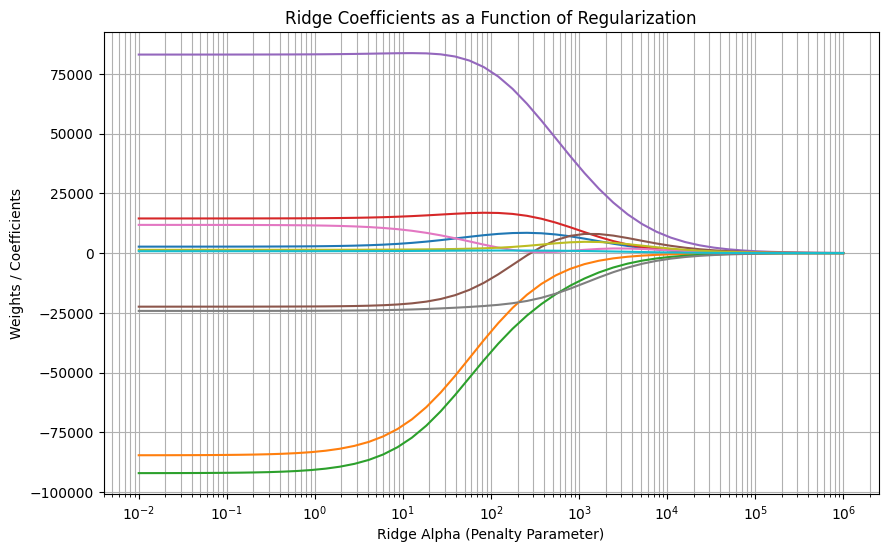

In [57]:
# Plot the coefficients
plt.figure(figsize=(10, 6))
plt.plot(ridge_reg_grid["ridge_reg__alpha"], coefs)

# Set X-axis to log scale since alphas are geometrically spaced
plt.xscale('log')

# Add styling and labels
plt.xlabel('Ridge Alpha (Penalty Parameter)')
plt.ylabel('Weights / Coefficients')
plt.title('Ridge Coefficients as a Function of Regularization')
plt.grid(True, which="both")
plt.show()

### 5. Fit Lasso regression

Fit the lasso regression (pipeline) on the training data previously created.

In [58]:
lasso_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['ocean_proximity_enc','longitude','latitude',...,'people_per_household', 'X1','X2']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Compute the root mean square error of the fitted model on both the training and test set. What do you observe?

In [59]:
# Print RMSE
print(root_mean_squared_error(y_train, lasso_pipe.predict(X_train)))
print(root_mean_squared_error(y_test, lasso_pipe.predict(X_test)))

# The values are almost the exact same as the Ridge regression, showing that the model is not overfitting and has low variance.

67636.07112819422
69642.05855737998


### 6. Plot Lasso coefficients

As above, we want to plot the coefficients of the lasso regression for different values of the penalty parameter.

Create a (geometrically spaced) grid, named `lasso_grid`, of penalty values ranging from `1` to `1e6`.

In [60]:
# Generates 50 geometrically spaced values
lasso_grid = {"lasso__alpha": list(np.logspace(1, 6, num=50))}
print(lasso_grid)

{'lasso__alpha': [np.float64(10.0), np.float64(12.648552168552959), np.float64(15.998587196060582), np.float64(20.235896477251575), np.float64(25.59547922699536), np.float64(32.374575428176435), np.float64(40.94915062380425), np.float64(51.794746792312125), np.float64(65.51285568595509), np.float64(82.86427728546842), np.float64(104.81131341546852), np.float64(132.57113655901094), np.float64(167.68329368110082), np.float64(212.09508879201903), np.float64(268.2695795279727), np.float64(339.32217718953297), np.float64(429.1934260128778), np.float64(542.867543932386), np.float64(686.6488450042998), np.float64(868.511373751353), np.float64(1098.5411419875584), np.float64(1389.4954943731375), np.float64(1757.510624854793), np.float64(2222.9964825261955), np.float64(2811.7686979742307), np.float64(3556.4803062231285), np.float64(4498.432668969444), np.float64(5689.866029018299), np.float64(7196.856730011521), np.float64(9102.981779915217), np.float64(11513.95399326448), np.float64(14563.4847

* Fill in the `??` below.

In [63]:
# Same but lasso
coefs = []
for alpha in lasso_grid["lasso__alpha"]:
    lasso_pipe.set_params(lasso__alpha = alpha)
    lasso_pipe.fit(X_train, y_train)
    coefs.append(lasso_pipe.named_steps['lasso'].coef_)



Plot the coefficients computed above.

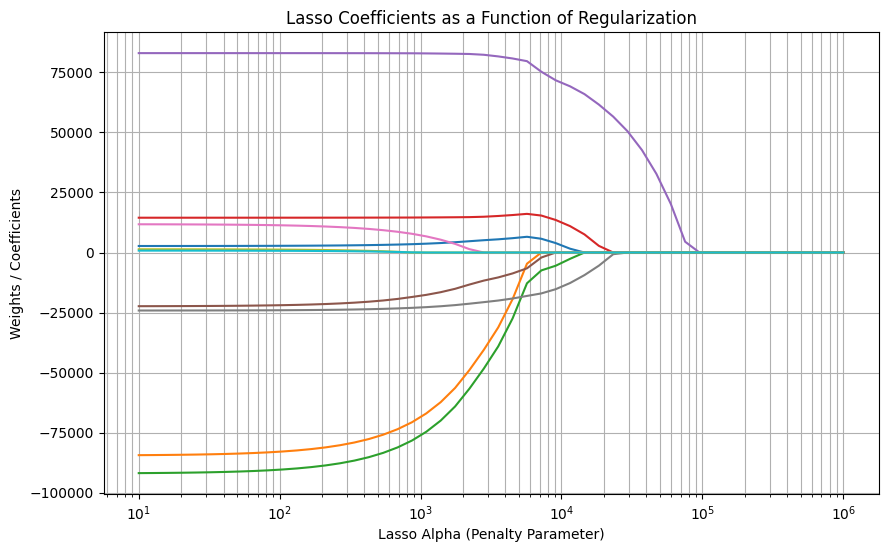

In [64]:
# Plot the coefficients
plt.figure(figsize=(10, 6))
plt.plot(lasso_grid["lasso__alpha"], coefs)

# Set X-axis to log scale since alphas are geometrically spaced
plt.xscale('log')

# Add styling and labels
plt.xlabel('Lasso Alpha (Penalty Parameter)')
plt.ylabel('Weights / Coefficients')
plt.title('Lasso Coefficients as a Function of Regularization')
plt.grid(True, which="both")
plt.show()

### 7. Prepare Cross Validation

At this point, we want to find the optimal penalty parameter for our models.
We will use 10-fold cross-validation.

Using the `KFold` class from `sklearn.model_selection` instatiate an object named `folds`.
Set the number of splits equal to 10, the random seed equal to 42, and make sure to shuffle the rows.

In [65]:
# Import
from sklearn.model_selection import KFold

# Instatiate folds with 10 splits, random 42
folds = KFold(n_splits=10, shuffle=True, random_state=42)


### 8. CV for Ridge

Create a dictionary with the key-value pair `"ridge_reg__alpha"`, `ridge_reg_grid`. What is the use of this object?

In [69]:
# already made but here is it again
ridge_reg_grid = {"ridge__alpha": list(np.logspace(-2, 6, num=50))}
print(ridge_reg_grid)
# Use to go over different values of alpha and see how the model performs with cross-validation.

{'ridge__alpha': [np.float64(0.01), np.float64(0.014563484775012436), np.float64(0.021209508879201904), np.float64(0.030888435964774818), np.float64(0.04498432668969444), np.float64(0.0655128556859551), np.float64(0.09540954763499938), np.float64(0.13894954943731375), np.float64(0.20235896477251566), np.float64(0.29470517025518095), np.float64(0.42919342601287763), np.float64(0.6250551925273969), np.float64(0.9102981779915218), np.float64(1.325711365590108), np.float64(1.9306977288832496), np.float64(2.811768697974228), np.float64(4.094915062380423), np.float64(5.963623316594643), np.float64(8.68511373751352), np.float64(12.648552168552959), np.float64(18.420699693267146), np.float64(26.826957952797247), np.float64(39.06939937054613), np.float64(56.89866029018293), np.float64(82.86427728546842), np.float64(120.67926406393289), np.float64(175.75106248547894), np.float64(255.95479226995332), np.float64(372.7593720314938), np.float64(542.867543932386), np.float64(790.6043210907685), np.fl

Import the class `GridSearchCV` from `sklearn.model_selection` and use it to instantiate a **cross-validation object** for the ridge regression. Make sure to include the following parameters: `estimator`, `param_grid`, `scoring`, `cv`.

In [70]:
from sklearn.model_selection import GridSearchCV

ridgeCV = GridSearchCV(estimator=ridge_pipe, param_grid=ridge_reg_grid, scoring="neg_mean_squared_error",
                       cv=folds)

Run the cross-validation by calling the `fit` method of the **cross-validation object** that you created at the point before.

In [71]:
# Fit
fit = ridgeCV.fit(X_train, y_train)

We want to plot the cross-validation error against different values of the penalty parameter. Fill in the `??`.

In [73]:
# Get results
resRCV = fit.cv_results_
# Choose best model that minimizes cv_err
mean_scores = -resRCV["mean_test_score"]
se_scores = resRCV["std_test_score"] / np.sqrt(10)
alphas = resRCV["param_ridge__alpha"].data

# View best alpha and 1-SD rule alpha
best_index = mean_scores.argmin()
min_alpha_ridge = alphas[best_index]
threshold_ridge = mean_scores[best_index] + se_scores[best_index] # add sd
one_se_rule_alpha_ridge = alphas[mean_scores <= threshold_ridge].max() # best in 1 sd rule

# Print
print("Minimum alpha:", min_alpha_ridge)
print("1-SD alpha:", one_se_rule_alpha_ridge)
print("Best score for ridge:", np.sqrt(np.min(mean_scores)))

Minimum alpha: 1.9306977288832496
1-SD alpha: 82.86427728546842
Best score for ridge: 68713.1827390045


### 9. CV for Lasso

Create a dictionary with the key-value pair `"lasso__alpha"`, `lasso_grid`. What is the use of this object?

In [74]:
# Same again
lasso_grid = {"lasso__alpha": list(np.logspace(1, 6, num=50))}
print(lasso_grid)

{'lasso__alpha': [np.float64(10.0), np.float64(12.648552168552959), np.float64(15.998587196060582), np.float64(20.235896477251575), np.float64(25.59547922699536), np.float64(32.374575428176435), np.float64(40.94915062380425), np.float64(51.794746792312125), np.float64(65.51285568595509), np.float64(82.86427728546842), np.float64(104.81131341546852), np.float64(132.57113655901094), np.float64(167.68329368110082), np.float64(212.09508879201903), np.float64(268.2695795279727), np.float64(339.32217718953297), np.float64(429.1934260128778), np.float64(542.867543932386), np.float64(686.6488450042998), np.float64(868.511373751353), np.float64(1098.5411419875584), np.float64(1389.4954943731375), np.float64(1757.510624854793), np.float64(2222.9964825261955), np.float64(2811.7686979742307), np.float64(3556.4803062231285), np.float64(4498.432668969444), np.float64(5689.866029018299), np.float64(7196.856730011521), np.float64(9102.981779915217), np.float64(11513.95399326448), np.float64(14563.4847

Create a cross-validation object for the lasso regression. Make sure to specify the following parameters: `estimator`, `param_grid`, `scoring`, `cv`.

In [75]:
from sklearn.model_selection import GridSearchCV

lassoCV = GridSearchCV(estimator=lasso_pipe, param_grid=lasso_grid, scoring="neg_mean_squared_error",
                       cv=folds)

Run the cross-validation by calling the `fit` method of the **cross-validation object** that you created at the point before.

In [76]:
# Fit
fitL = lassoCV.fit(X_train, y_train)

We want to plot the cross-validation error against different values of the penalty parameter. Fill in the `??`.

In [81]:
# Get results
resLCV = fitL.cv_results_

# Choose best model that minimizes the cv_err
mean_scores = -resLCV["mean_test_score"]
se_scores = resLCV["std_test_score"] / np.sqrt(10)
alphas = resLCV["param_lasso__alpha"].data

best_index = mean_scores.argmin()
min_alpha_lasso = alphas[best_index]
threshold_lasso = mean_scores[best_index] + se_scores[best_index] # add sd
one_se_rule_alpha_lasso = alphas[mean_scores <= threshold_ridge].max() # best in 1 sd rule

print("Minimum alpha:", min_alpha_lasso)
print("1-SD alpha:", one_se_rule_alpha_lasso)
print("Best score for lasso:", np.sqrt(np.min(mean_scores)))

Minimum alpha: 268.2695795279727
1-SD alpha: 3556.4803062231285
Best score for lasso: 68694.05400273637


### 10. Compute performance of the two best models

Given the optimal tuning parameter of the ridge and lasso regression, refit both models on the entire training data set.
Furthermore, compute their root mean square error on the test set. How do they compare to the errors obtained before performing the cross-validation?


In [88]:
# Refit best ridge on whole training data and evaluate on test
 # Fit Ridge regression
ModelRFinal = Ridge(alpha=one_se_rule_alpha_ridge, fit_intercept=True)

# Initialize pipeline R
ridge_pipe_final = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', ModelRFinal)
])

# Fit
ridge_pipe_final.fit(X_train, y_train)

# Print RMSE
print(root_mean_squared_error(y_train, ridge_pipe_final.predict(X_train)))
print(root_mean_squared_error(y_test, ridge_pipe_final.predict(X_test)))


70227.4850903789
72136.57014259844


In [ ]:
# Refit best lasso on whole training data and evaluate on test
 # Fit Lasso regression
ModelLFinal = Lasso(alpha=one_se_rule_alpha_lasso, fit_intercept=True)

# Initialize pipeline R
lasso_pipe_final = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', ModelLFinal)
])

# Fit
lasso_pipe_final.fit(X_train, y_train)

# Print RMSE
print(root_mean_squared_error(y_train, lasso_pipe_final.predict(X_train)))
print(root_mean_squared_error(y_test, lasso_pipe_final.predict(X_test)))

# Both are a little higher than the first model, but are significantly simpler through shrinkage and elimination, thus leading to less sensitive / more robust results.

70791.20374347543
72083.33197913729


## Problem 2

In this problem, you are asked to derive the closed-form solution for the ridge regression coefficients.

Let $\mathbf{X}\in\mathbb{R}^{n\times p}$ denote the matrix of predictors, and let $\mathbf{y}\in\mathbb{R}^n$ denote the target vector.

The optimal ridge regression coefficient vector $\beta^*$, with parameter $\lambda > 0$, is defined as

$$\beta^* := \arg\min_{\beta\in\mathbb{R}^p} \ (\mathbf{y} - \mathbf{X}\beta)^T(\mathbf{y} - \mathbf{X}\beta) + \lambda \beta ^T\beta.$$

Show that 


$$\beta^*  = (\mathbf{X}^T\mathbf{X} + \lambda \mathbf{I}_p)^{-1} \mathbf{X}^T \mathbf{y},$$

where $\mathbf{I}_p$ denote the identity matrix of size $p\times p$.